In [13]:
# EVALUATION TABLES AND FIGURES

# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, fbeta_score
)
import warnings
import os
warnings.filterwarnings('ignore')

In [14]:
BETA=2

In [15]:
# import pandas as pd
# import glob
# import os
#
# # Define the file pattern and get all matching files
# file_pattern = "../patient_agent_results/predictions/predictions_*.csv"
# csv_files = glob.glob(file_pattern)
#
# # Sort files to ensure consistent order (optional, since we'll sort by ID anyway)
# csv_files.sort()
#
# print(f"Found {len(csv_files)} files: {csv_files}")
#
# # Read and concatenate all CSV files
# dataframes = []
# for file in csv_files:
#     df = pd.read_csv(file)
#     print(f"Loaded {file}: {len(df)} rows")
#     dataframes.append(df)
#
# # Concatenate all dataframes
# combined_df = pd.concat(dataframes, ignore_index=True)
#
# # Sort by ID
# combined_df = combined_df.sort_values('id').reset_index(drop=True)
#
# print(f"\nCombined dataset: {len(combined_df)} rows")
# print(f"ID range: {combined_df['id'].min()} to {combined_df['id'].max()}")
#
# # Save the combined and sorted dataset
# output_file = "../patient_agent_results/predictions/prediction_combined.csv"
# combined_df.to_csv(output_file, index=False)
#
# print(f"\nSaved combined dataset to: {output_file}")
#
# # Display first few rows to verify
# print("\nFirst 5 rows:")
# print(combined_df.head())
#
# # Display last few rows to verify
# print("\nLast 5 rows:")
# print(combined_df.tail())

In [16]:
# Configuration
RESULTS_PATH = "../patient_agent_results/prediction_combined_all_modules.csv"
FIGURES_OUTPUT_DIR = "./figures"  # Directory to save figures

# Create figures directory if it doesn't exist
os.makedirs(FIGURES_OUTPUT_DIR, exist_ok=True)


In [17]:
def load_and_inspect_data(filepath):
    """Load and perform basic inspection of the dataset."""
    df = pd.read_csv(filepath)

    print("Dataset Shape:", df.shape)
    print("\nColumn Names:")
    print(df.columns.tolist())
    print("\nFirst few rows:")
    print(df.head())
    print("\nData Types:")
    print(df.dtypes)
    print("\nMissing Values:")
    print(df.isnull().sum())
    print("\nUnique values in key columns:")

    key_columns = ['Module', 'Tier of Symptom Disclosure', 'Expected Symptom Direction', 'Emotion/Tone Tier']
    for col in key_columns:
        if col in df.columns:
            print(f"{col}: {df[col].nunique()} unique values")
            print(f"  {df[col].unique()}")
            print()

    return df


In [18]:
def normalize_labels(df):
    """Normalize labels to consistent 0/1 format."""
    df_work = df.copy()
    label_map = {'yes': 1, 'no': 0, True: 1, False: 0, 1: 1, 0: 0}

    df_work['label_int'] = df_work['label'].map(label_map)
    df_work['prediction_int'] = df_work['prediction'].map(label_map)

    # Handle unmapped values
    if df_work[['label_int', 'prediction_int']].isna().any().any():
        print("Warning: Some labels could not be mapped. Filling with original values.")
        df_work['label_int'] = df_work['label_int'].fillna(df_work['label'].astype(int))
        df_work['prediction_int'] = df_work['prediction_int'].fillna(df_work['prediction'].astype(int))

    return df_work


In [19]:
def calculate_basic_metrics(df):
    """Calculate and display basic classification metrics."""
    y_true = df['label_int'].astype(int)
    y_pred = df['prediction_int'].astype(int)

    # Calculate confusion matrix components
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    # Calculate metrics
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f2': fbeta_score(y_true, y_pred, beta=BETA, zero_division=0)
    }

    # Display results
    print("=== CONFUSION MATRIX COMPONENTS ===")
    print(f"True Positives (TP):  {tp}")
    print(f"True Negatives (TN):  {tn}")
    print(f"False Positives (FP): {fp}")
    print(f"False Negatives (FN): {fn}")
    print(f"Total Samples: {tp + tn + fp + fn}")

    print("\n=== PERFORMANCE METRICS ===")
    for metric_name, value in metrics.items():
        print(f"{metric_name.capitalize():10}: {value:.4f} ({value*100:.2f}%)")

    # Create summary table
    metrics_summary = pd.DataFrame({
        'Metric': ['TP', 'TN', 'FP', 'FN'] + list(metrics.keys()),
        'Value': [tp, tn, fp, fn] + list(metrics.values()),
        'Percentage': [f"{x/(tp+tn+fp+fn)*100:.2f}%" for x in [tp, tn, fp, fn]] +
                     [f"{v*100:.2f}%" for v in metrics.values()]
    })

    print("\n=== METRICS SUMMARY TABLE ===")
    print(metrics_summary)

    return metrics_summary


In [20]:
def save_figure(fig, filename_base, output_dir=FIGURES_OUTPUT_DIR):
    """
    Save figure in both SVG and JPG formats with 600 DPI.

    Args:
        fig: matplotlib figure object
        filename_base: base filename without extension
        output_dir: directory to save figures
    """
    # Clean filename - remove special characters and replace spaces with underscores
    clean_filename = "".join(c for c in filename_base if c.isalnum() or c in (' ', '-', '_')).rstrip()
    clean_filename = clean_filename.replace(' ', '_')

    # Save as SVG (vector format, inherently high quality)
    svg_path = os.path.join(output_dir, f"{clean_filename}.svg")
    fig.savefig(svg_path, format='svg', bbox_inches='tight', pad_inches=0.1)
    print(f"Saved SVG: {svg_path}")

    # Save as JPG with 600 DPI
    jpg_path = os.path.join(output_dir, f"{clean_filename}.jpg")
    fig.savefig(jpg_path, format='jpg', dpi=600, bbox_inches='tight',
                pad_inches=0.1, facecolor='white', edgecolor='none')
    print(f"Saved JPG: {jpg_path}")


In [21]:
def create_metric_matrix(df, row_col, col_col, title_suffix, metric='f2'):
    """
    Create metric score matrix for two categorical variables.

    Args:
        df: DataFrame with normalized labels
        row_col: Column name for matrix rows
        col_col: Column name for matrix columns
        title_suffix: Suffix for plot title
        metric: 'f2' or 'accuracy'
    """
    # Ensure required columns exist
    required_cols = [row_col, col_col, 'label_int', 'prediction_int']
    df_clean = df.dropna(subset=required_cols)

    if df_clean.empty:
        print(f"No data available for {row_col} × {col_col} analysis")
        return None

    # Get unique values
    rows = sorted(df_clean[row_col].unique())
    cols = sorted(df_clean[col_col].unique())

    # Initialize matrix
    metric_matrix = pd.DataFrame(index=rows, columns=cols, dtype=float)

    # Calculate metric scores
    for row_val in rows:
        for col_val in cols:
            subset = df_clean[
                (df_clean[row_col] == row_val) &
                (df_clean[col_col] == col_val)
            ]

            if subset.empty:
                metric_matrix.loc[row_val, col_val] = np.nan
                continue

            y_true = subset['label_int'].to_numpy()
            y_pred = subset['prediction_int'].to_numpy()

            # Calculate metric
            if metric == 'f2':
                score = fbeta_score(y_true, y_pred, beta=BETA, average='binary', zero_division=0)
            elif metric == 'accuracy':
                score = accuracy_score(y_true, y_pred)
            else:
                raise ValueError(f"Unsupported metric: {metric}")

            metric_matrix.loc[row_val, col_val] = score

    # Display results
    metric_name = metric.upper()
    print(f"{metric_name} Score Matrix ({row_col} × {col_col})")
    print("=" * 50)
    print(metric_matrix.round(4))

    # Summary statistics
    finite_values = metric_matrix.values[np.isfinite(metric_matrix.values)]
    if len(finite_values) > 0:
        overall_mean = finite_values.mean()
        print(f"\nOverall mean {metric_name}: {overall_mean:.4f}")

        stacked = metric_matrix.stack()
        max_pos = stacked.idxmax()
        min_pos = stacked.idxmin()
        print(f"Best: {max_pos[0]} × {max_pos[1]} = {stacked[max_pos]:.4f}")
        print(f"Worst: {min_pos[0]} × {min_pos[1]} = {stacked[min_pos]:.4f}")

    # Create heatmap and save figure
    fig = plot_metric_heatmap(metric_matrix, row_col, col_col, title_suffix, metric)

    # Generate filename for saving
    filename_base = f"{metric}_{row_col}_vs_{col_col}_heatmap"
    save_figure(fig, filename_base)

    return metric_matrix


In [22]:
def plot_metric_heatmap(metric_matrix, row_label, col_label, title_suffix, metric='f2'):
    """Create and display metric score heatmap with consistent formatting."""
    # Add mean columns and rows
    metric_plot = metric_matrix.copy()
    metric_plot['Mean'] = metric_plot.mean(axis=1, skipna=True)
    mean_row = metric_plot.mean(axis=0, skipna=True)
    mean_row.name = 'Mean'
    metric_plot = pd.concat([metric_plot, mean_row.to_frame().T])

    # Convert to percentage format for display
    metric_plot_percent = metric_plot * 100

    # Calculate consistent figure size based on matrix dimensions
    n_cols = len(metric_plot.columns)
    n_rows = len(metric_plot.index)
    fig_width = max(8, n_cols * 0.8)  # Minimum width 8, scale with columns
    fig_height = max(5, n_rows * 0.6)  # Minimum height 5, scale with rows

    # Create plot with consistent sizing
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    # Set font to Helvetica globally
    plt.rcParams['font.family'] = 'Helvetica'
    plt.rcParams['font.size'] = 10

    # Create custom colormap from light blue (0.5) to darker blue (1.0)
    from matplotlib.colors import LinearSegmentedColormap
    blues_custom = plt.cm.Blues(np.linspace(0.3, 0.9, 256))  # Light blue to readable dark blue
    custom_cmap = LinearSegmentedColormap.from_list('custom_blues', blues_custom)

    sns.heatmap(
        metric_plot_percent,  # Use percentage values
        annot=True,
        cmap=custom_cmap,
        fmt='.1f',  # One decimal place for percentages
        vmin=50.0,  # Min value 50% instead of 0%
        vmax=100.0,  # Max value 100%
        cbar_kws={
            'label': f'{metric.upper()} Score (%)',
            'shrink': 0.8  # Smaller colorbar
        },
        linewidths=0.2,  # Very thin lines for condensed look
        linecolor='white',
        square=True,  # Square cells for consistency
        ax=ax,
        annot_kws={
            'fontsize': 10,
            'fontfamily': 'Helvetica',
            'fontweight': 'bold'  # Bold numbers for better readability
        }
    )

    # Formatting with Helvetica font
    metric_name = metric.upper()
    ax.set_title(f'{metric_name} Score: {title_suffix}',
                fontsize=10, fontweight='bold', pad=10, fontfamily='Helvetica')
    ax.set_xlabel(col_label, fontsize=10, fontweight='bold', fontfamily='Helvetica')
    ax.set_ylabel(row_label, fontsize=10, fontweight='bold', fontfamily='Helvetica')

    # Adjust tick labels with Helvetica font
    ax.set_xticklabels(ax.get_xticklabels(),
                      rotation=45, ha='right', fontsize=10, fontfamily='Helvetica')
    ax.set_yticklabels(ax.get_yticklabels(),
                      rotation=0, fontsize=10, fontfamily='Helvetica')

    # Colorbar tick labels also Helvetica
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=10)
    for label in cbar.ax.get_yticklabels():
        label.set_fontfamily('Helvetica')
    cbar.ax.yaxis.label.set_fontfamily('Helvetica')
    cbar.ax.yaxis.label.set_fontsize(10)

    # Very tight layout with minimal padding
    plt.tight_layout(pad=0.5)
    plt.subplots_adjust(left=0.1, right=0.95, top=0.92, bottom=0.15)
    plt.show()

    return fig  # Return figure object for saving


In [23]:
def main():
    """Main analysis pipeline."""
    # Load and inspect data
    print("Loading and inspecting data...")
    df = load_and_inspect_data(RESULTS_PATH)

    # Normalize labels
    print("\nNormalizing labels...")
    df_normalized = normalize_labels(df)

    # Calculate basic metrics
    print("\nCalculating basic classification metrics...")
    metrics_summary = calculate_basic_metrics(df_normalized)

    # Create metric matrices for different variable combinations
    analyses = [
        ('Module', 'Tier of Symptom Disclosure', 'Performance by Module and Symptom Disclosure Tier'),
        ('Module', 'Expected Symptom Direction', 'Performance by Module and Expected Symptom Direction'),
        ('Module', 'Emotion/Tone Tier', 'Performance by Module and Emotion/Tone Tier')
    ]

    f2_matrices = {}
    accuracy_matrices = {}

    print(f"\nFigures will be saved to: {os.path.abspath(FIGURES_OUTPUT_DIR)}")
    print("="*60)

    for row_col, col_col, title in analyses:
        if row_col in df.columns and col_col in df.columns:
            print(f"\n{'='*60}")
            print(f"Analysis: {title}")
            print('='*60)

            # f2 Score Analysis
            print("\nf2 SCORE ANALYSIS:")
            f2_matrix = create_metric_matrix(df_normalized, row_col, col_col, title, 'f2')
            if f2_matrix is not None:
                f2_matrices[f"{row_col}_{col_col}"] = f2_matrix

            # Accuracy Analysis
            print("\nACCURACY ANALYSIS:")
            accuracy_matrix = create_metric_matrix(df_normalized, row_col, col_col, title, 'accuracy')
            if accuracy_matrix is not None:
                accuracy_matrices[f"{row_col}_{col_col}"] = accuracy_matrix
        else:
            print(f"Skipping {row_col} × {col_col}: columns not found")

    print(f"\n{'='*60}")
    print("ANALYSIS COMPLETE")
    print(f"All figures saved to: {os.path.abspath(FIGURES_OUTPUT_DIR)}")
    print("="*60)

    return df_normalized, metrics_summary, f2_matrices, accuracy_matrices


Loading and inspecting data...
Dataset Shape: (1349, 7)

Column Names:
['id', 'label', 'prediction', 'Module', 'Tier of Symptom Disclosure', 'Expected Symptom Direction', 'Emotion/Tone Tier']

First few rows:
   id  label  prediction                        Module  \
0   1   True        True  A - Major Depressive Episode   
1   2   True        True  A - Major Depressive Episode   
2   3   True        True  A - Major Depressive Episode   
3   4   True        True  A - Major Depressive Episode   
4   5   True        True  A - Major Depressive Episode   

  Tier of Symptom Disclosure     Expected Symptom Direction  \
0  Tier 1: Superficial/Vague  Positive Symptom Presentation   
1  Tier 1: Superficial/Vague  Positive Symptom Presentation   
2  Tier 1: Superficial/Vague  Positive Symptom Presentation   
3  Tier 1: Superficial/Vague  Positive Symptom Presentation   
4  Tier 1: Superficial/Vague  Positive Symptom Presentation   

     Emotion/Tone Tier  
0        Flat/Detached  
1        Flat

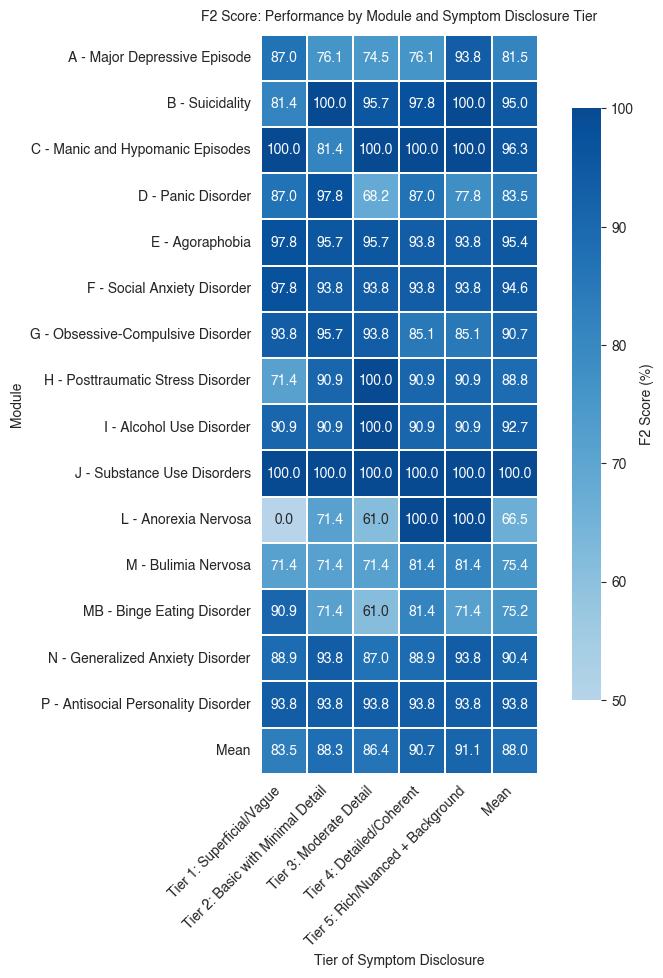

Saved SVG: ./figures/f2_Module_vs_Tier_of_Symptom_Disclosure_heatmap.svg
Saved JPG: ./figures/f2_Module_vs_Tier_of_Symptom_Disclosure_heatmap.jpg

ACCURACY ANALYSIS:
ACCURACY Score Matrix (Module × Tier of Symptom Disclosure)
                                     Tier 1: Superficial/Vague  \
A - Major Depressive Episode                            0.8333   
B - Suicidality                                         0.8889   
C - Manic and Hypomanic Episodes                        1.0000   
D - Panic Disorder                                      0.8333   
E - Agoraphobia                                         0.9444   
F - Social Anxiety Disorder                             0.9444   
G - Obsessive-Compulsive Disorder                       0.8333   
H - Posttraumatic Stress Disorder                       0.8333   
I - Alcohol Use Disorder                                0.9444   
J - Substance Use Disorders                             1.0000   
L - Anorexia Nervosa                            

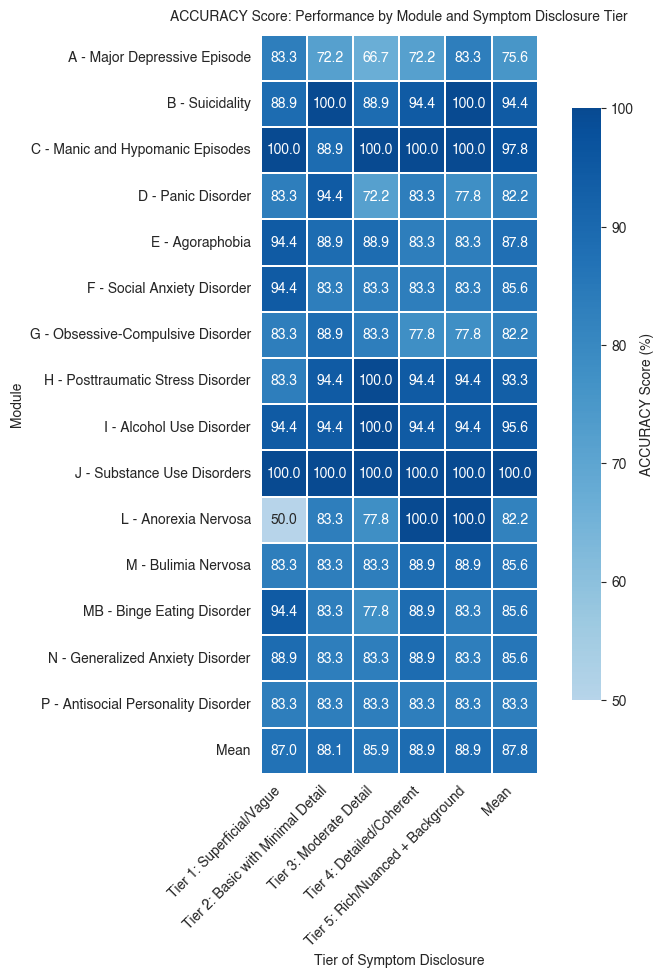

Saved SVG: ./figures/accuracy_Module_vs_Tier_of_Symptom_Disclosure_heatmap.svg
Saved JPG: ./figures/accuracy_Module_vs_Tier_of_Symptom_Disclosure_heatmap.jpg

Analysis: Performance by Module and Expected Symptom Direction

f2 SCORE ANALYSIS:
F2 Score Matrix (Module × Expected Symptom Direction)
                                     Negative Symptom Presentation  \
A - Major Depressive Episode                                   0.0   
B - Suicidality                                                0.0   
C - Manic and Hypomanic Episodes                               0.0   
D - Panic Disorder                                             0.0   
E - Agoraphobia                                                0.0   
F - Social Anxiety Disorder                                    0.0   
G - Obsessive-Compulsive Disorder                              0.0   
H - Posttraumatic Stress Disorder                              0.0   
I - Alcohol Use Disorder                                       0.0   
J - 

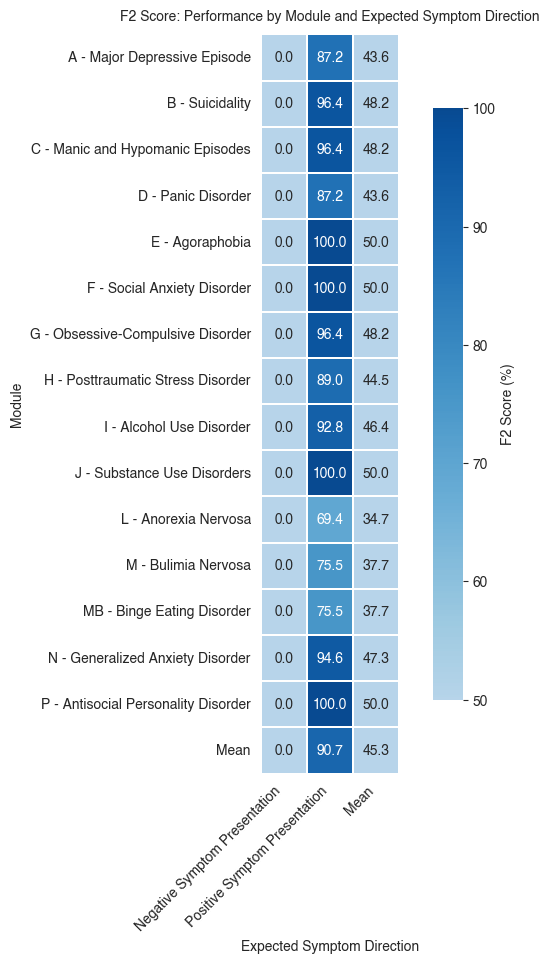

Saved SVG: ./figures/f2_Module_vs_Expected_Symptom_Direction_heatmap.svg
Saved JPG: ./figures/f2_Module_vs_Expected_Symptom_Direction_heatmap.jpg

ACCURACY ANALYSIS:
ACCURACY Score Matrix (Module × Expected Symptom Direction)
                                     Negative Symptom Presentation  \
A - Major Depressive Episode                                0.6667   
B - Suicidality                                             0.9333   
C - Manic and Hypomanic Episodes                            1.0000   
D - Panic Disorder                                          0.8000   
E - Agoraphobia                                             0.7556   
F - Social Anxiety Disorder                                 0.7111   
G - Obsessive-Compulsive Disorder                           0.6889   
H - Posttraumatic Stress Disorder                           1.0000   
I - Alcohol Use Disorder                                    1.0000   
J - Substance Use Disorders                                 1.0000   
L - 

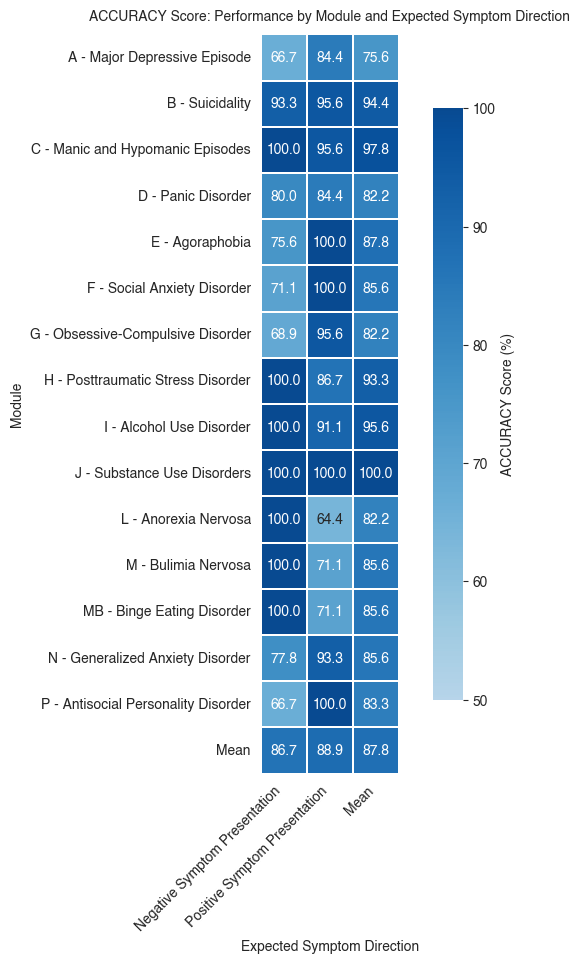

Saved SVG: ./figures/accuracy_Module_vs_Expected_Symptom_Direction_heatmap.svg
Saved JPG: ./figures/accuracy_Module_vs_Expected_Symptom_Direction_heatmap.jpg

Analysis: Performance by Module and Emotion/Tone Tier

f2 SCORE ANALYSIS:
F2 Score Matrix (Module × Emotion/Tone Tier)
                                     Emotional/Expressive  Flat/Detached  \
A - Major Depressive Episode                       0.7692         0.8442   
B - Suicidality                                    0.9333         0.9333   
C - Manic and Hypomanic Episodes                   1.0000         0.8904   
D - Panic Disorder                                 0.8442         0.8000   
E - Agoraphobia                                    0.9494         0.9494   
F - Social Anxiety Disorder                        0.9375         0.9494   
G - Obsessive-Compulsive Disorder                  0.9375         0.8861   
H - Posttraumatic Stress Disorder                  0.8904         0.8904   
I - Alcohol Use Disorder              

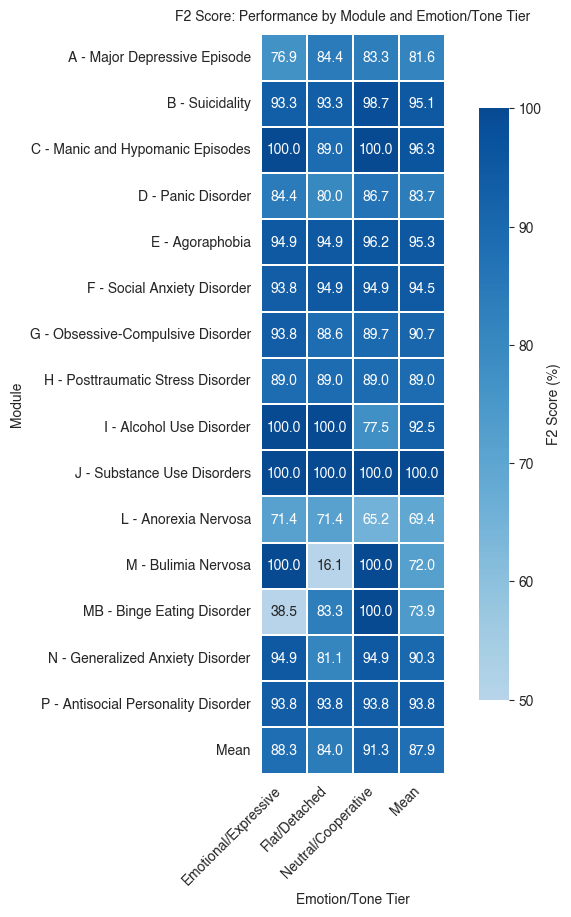

Saved SVG: ./figures/f2_Module_vs_EmotionTone_Tier_heatmap.svg
Saved JPG: ./figures/f2_Module_vs_EmotionTone_Tier_heatmap.jpg

ACCURACY ANALYSIS:
ACCURACY Score Matrix (Module × Emotion/Tone Tier)
                                     Emotional/Expressive  Flat/Detached  \
A - Major Depressive Episode                       0.7000         0.8000   
B - Suicidality                                    0.9333         0.9333   
C - Manic and Hypomanic Episodes                   1.0000         0.9333   
D - Panic Disorder                                 0.8000         0.8000   
E - Agoraphobia                                    0.8667         0.8667   
F - Social Anxiety Disorder                        0.8333         0.8667   
G - Obsessive-Compulsive Disorder                  0.8333         0.8000   
H - Posttraumatic Stress Disorder                  0.9333         0.9333   
I - Alcohol Use Disorder                           1.0000         1.0000   
J - Substance Use Disorders                

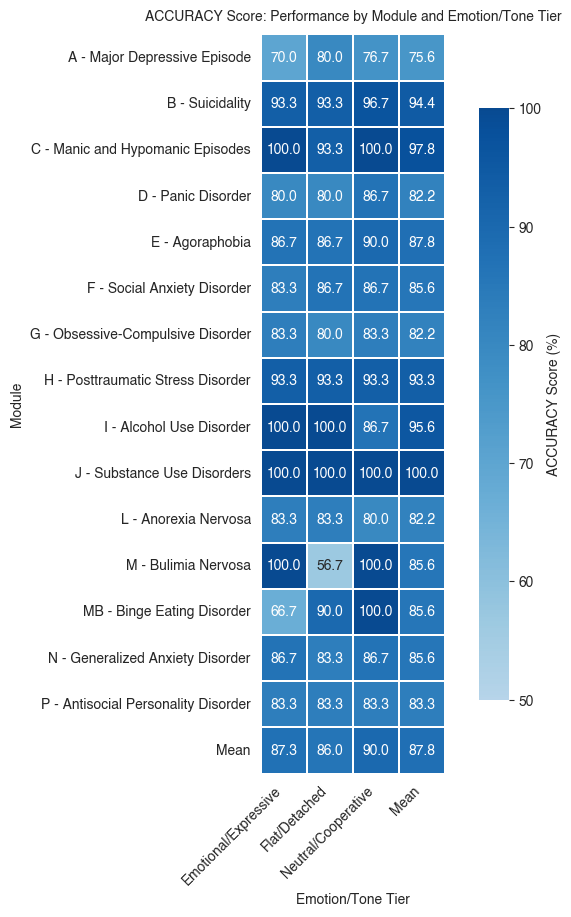

Saved SVG: ./figures/accuracy_Module_vs_EmotionTone_Tier_heatmap.svg
Saved JPG: ./figures/accuracy_Module_vs_EmotionTone_Tier_heatmap.jpg

ANALYSIS COMPLETE
All figures saved to: /Users/rezabarzegar/PycharmProjects/mini-agent/notebooks/figures


In [24]:
# Run the analysis
if __name__ == "__main__":
    df_final, metrics, f2_matrices, accuracy_matrices = main()